First 5 Rows:
   Product_ID   Sale_Date Sales_Rep Region  Sales_Amount  Quantity_Sold  \
0        1052  2023-02-03       Bob  North       5053.97             18   
1        1093  2023-04-21       Bob   West       4384.02             17   
2        1015  2023-09-21     David  South       4631.23             30   
3        1072  2023-08-24       Bob  South       2167.94             39   
4        1061  2023-03-24   Charlie   East       3750.20             13   

  Product_Category  Unit_Cost  Unit_Price Customer_Type  Discount  \
0        Furniture     152.75      267.22     Returning      0.09   
1        Furniture    3816.39     4209.44     Returning      0.11   
2             Food     261.56      371.40     Returning      0.20   
3         Clothing    4330.03     4467.75           New      0.02   
4      Electronics     637.37      692.71           New      0.08   

  Payment_Method Sales_Channel Region_and_Sales_Rep  
0           Cash        Online            North-Bob  
1           

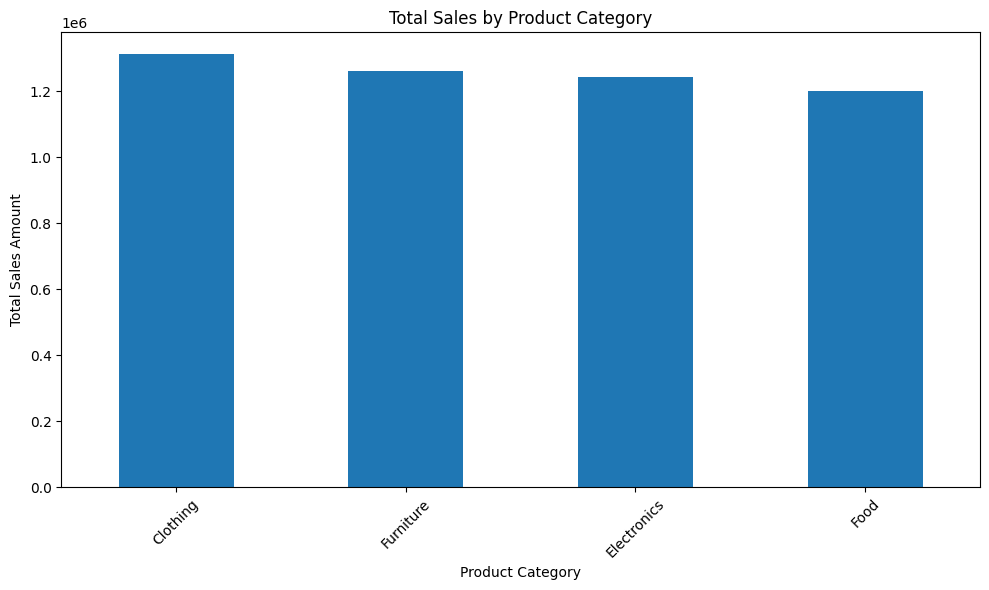

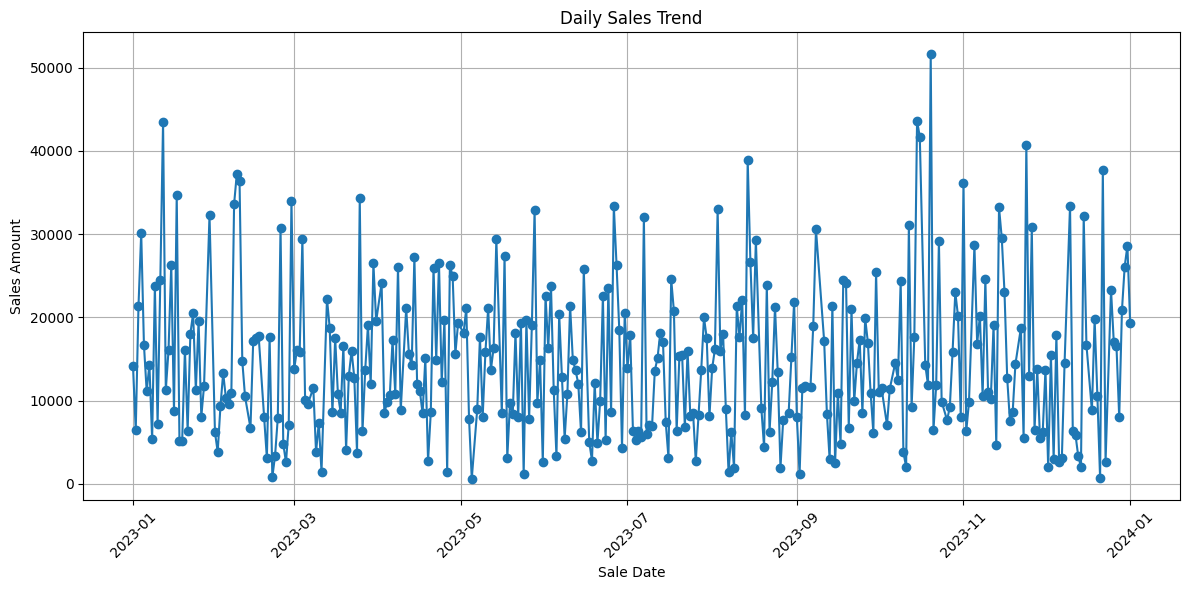

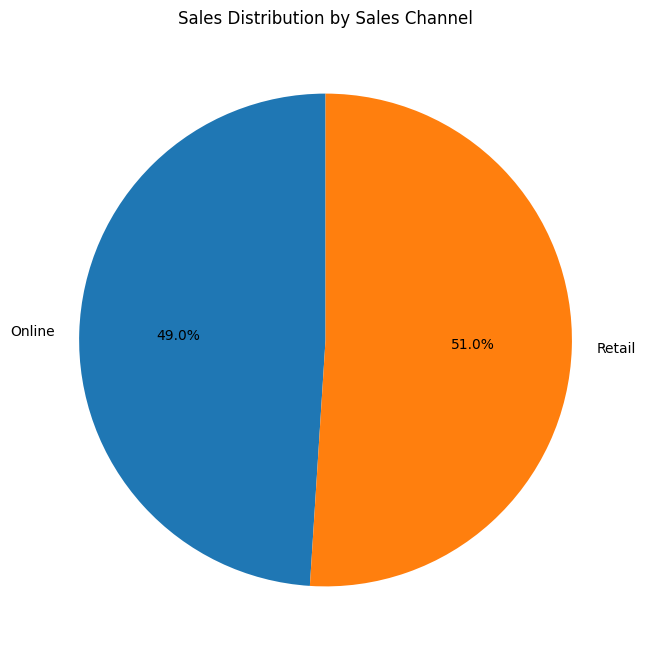

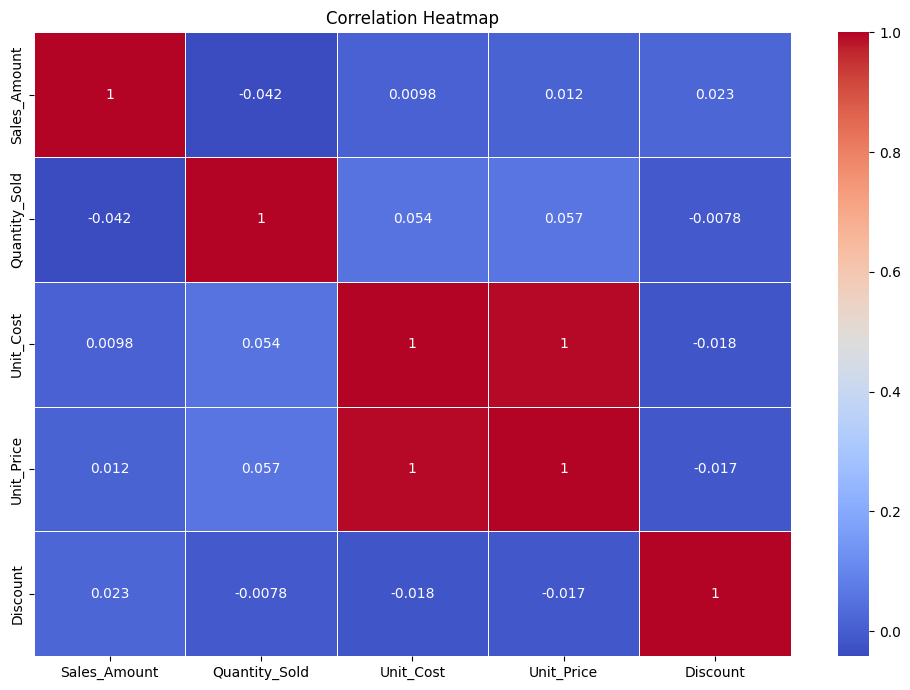


MODEL PERFORMANCE
Mean Absolute Error (MAE): 7850.619235327698
R2 Score: -0.006129814682597212

Actual vs Predicted Sales:
   Actual Sales  Predicted Sales
0       6283.68     15084.489347
1       8959.30     14831.730213
2      21093.68     14826.081964
3      17488.57     14717.353174
4       3098.87     14847.262897
5      11454.13     14999.765615
6      18167.39     14926.338380
7       9267.63     15076.016974
8      26107.95     15166.388955
9       8058.99     14689.111930


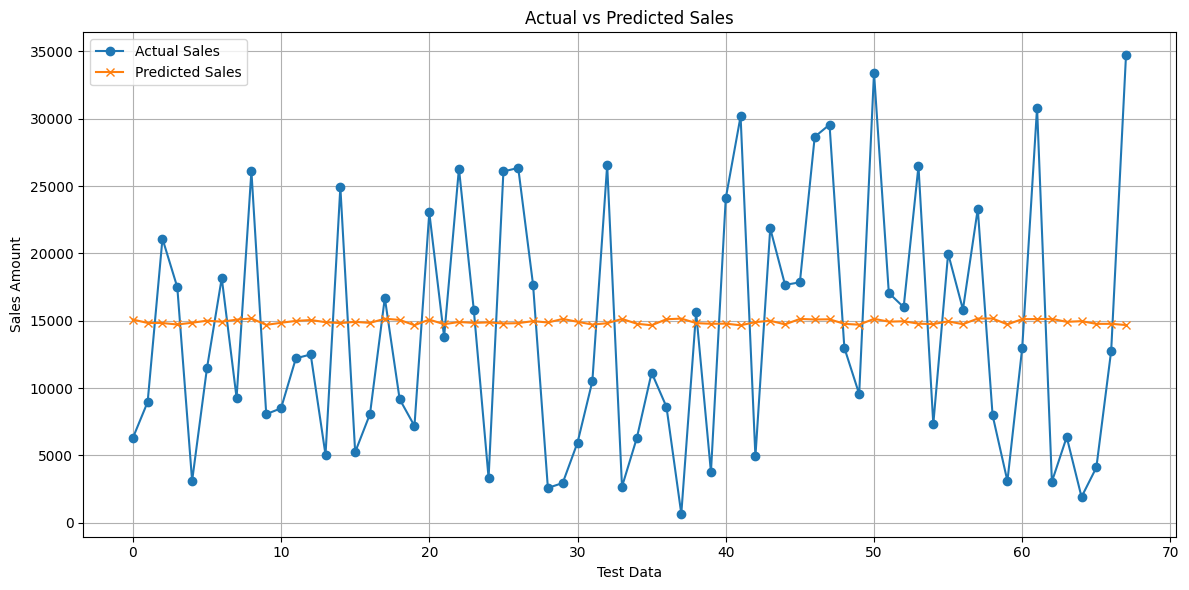


NEXT 10 DAYS FUTURE SALES
        Date  Predicted_Sales
0 2024-01-02     15170.625141
1 2024-01-03     15172.037203
2 2024-01-04     15173.449266
3 2024-01-05     15174.861328
4 2024-01-06     15176.273390
5 2024-01-07     15177.685452
6 2024-01-08     15179.097514
7 2024-01-09     15180.509577
8 2024-01-10     15181.921639
9 2024-01-11     15183.333701


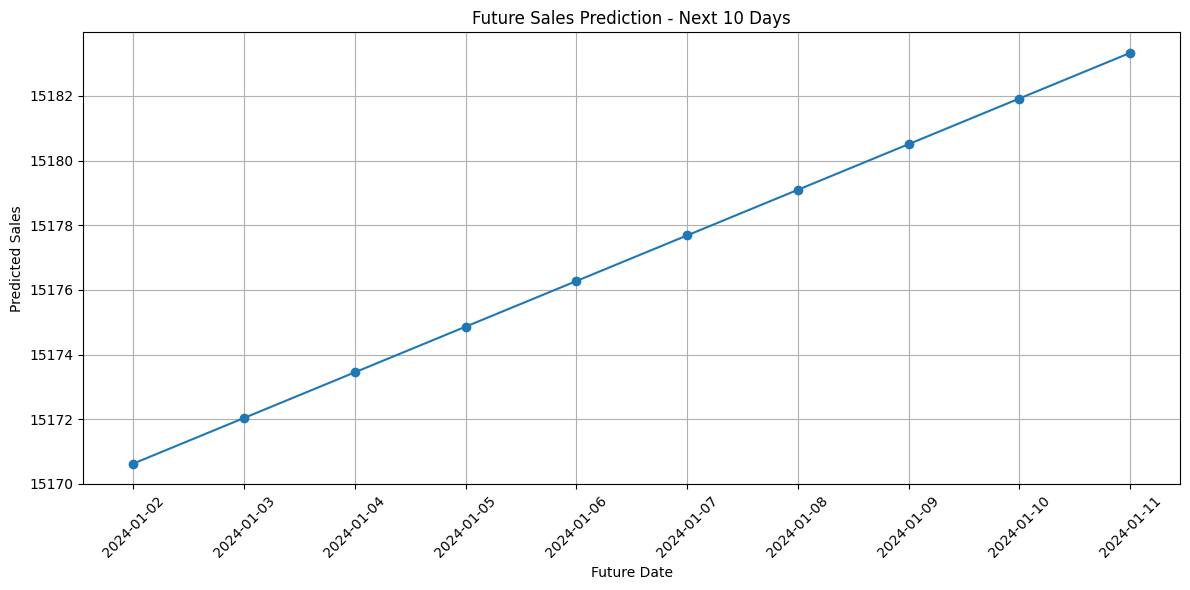


Future predictions saved successfully!


In [ ]:
# ============================================================
# FUTURE SALES PREDICTION
# ============================================================

# -----------------------------
# 1. Import Libraries
# -----------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


# -----------------------------
# 2. Load Dataset
# -----------------------------

df = pd.read_csv("sales_data.csv")

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())


# -----------------------------
# 3. Convert Sale_Date
# -----------------------------

df["Sale_Date"] = pd.to_datetime(df["Sale_Date"])

# Sort by date
df = df.sort_values("Sale_Date")


# -----------------------------
# 4. Basic Statistics
# -----------------------------

print("\nStatistical Summary:")
print(df.describe())


# ============================================================
# 5. BAR CHART
# Sales by Product Category
# ============================================================

category_sales = df.groupby(
    "Product_Category"
)["Sales_Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

category_sales.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 6. LINE CHART
# Daily Sales Trend
# ============================================================

daily_sales = df.groupby(
    "Sale_Date"
)["Sales_Amount"].sum()

plt.figure(figsize=(12, 6))

plt.plot(
    daily_sales.index,
    daily_sales.values,
    marker="o"
)

plt.title("Daily Sales Trend")
plt.xlabel("Sale Date")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. PIE CHART
# Sales by Sales Channel
# ============================================================

channel_sales = df.groupby(
    "Sales_Channel"
)["Sales_Amount"].sum()

plt.figure(figsize=(8, 8))

plt.pie(
    channel_sales.values,
    labels=channel_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Distribution by Sales Channel")

plt.show()


# ============================================================
# 8. HEATMAP
# Correlation between numerical columns
# ============================================================

numeric_columns = [
    "Sales_Amount",
    "Quantity_Sold",
    "Unit_Cost",
    "Unit_Price",
    "Discount"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()


# ============================================================
# 9. PREPARE DATA FOR FUTURE SALES PREDICTION
# ============================================================

# Aggregate sales by date

daily_sales = df.groupby(
    "Sale_Date"
)["Sales_Amount"].sum().reset_index()

daily_sales = daily_sales.sort_values("Sale_Date")


# Create numerical date feature

daily_sales["Date_Number"] = (
    daily_sales["Sale_Date"] -
    daily_sales["Sale_Date"].min()
).dt.days


# -----------------------------
# Features and Target
# -----------------------------

X = daily_sales[["Date_Number"]]

y = daily_sales["Sales_Amount"]


# ============================================================
# 10. Train-Test Split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ============================================================
# 11. Create Linear Regression Model
# ============================================================

model = LinearRegression()

model.fit(X_train, y_train)


# ============================================================
# 12. Prediction on Test Data
# ============================================================

y_pred = model.predict(X_test)


# ============================================================
# 13. Model Evaluation
# ============================================================

mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("\n==============================")
print("MODEL PERFORMANCE")
print("==============================")

print("Mean Absolute Error (MAE):", mae)

print("R2 Score:", r2)


# ============================================================
# 14. ACTUAL VS PREDICTED SALES
# ============================================================

comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

print("\nActual vs Predicted Sales:")
print(comparison.head(10))


# ============================================================
# 15. ACTUAL VS PREDICTED LINE CHART
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    y_pred,
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Sales")

plt.xlabel("Test Data")

plt.ylabel("Sales Amount")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 16. FUTURE SALES PREDICTION
# Predict next 10 days
# ============================================================

last_date = daily_sales["Sale_Date"].max()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=10,
    freq="D"
)


# Convert future dates to numerical values

future_date_numbers = (
    future_dates -
    daily_sales["Sale_Date"].min()
).days


future_X = pd.DataFrame({
    "Date_Number": future_date_numbers
})


# Predict future sales

future_predictions = model.predict(future_X)


# ============================================================
# 17. CREATE FUTURE SALES TABLE
# ============================================================

future_sales = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Sales": future_predictions
})


print("\n==============================")
print("NEXT 10 DAYS FUTURE SALES")
print("==============================")

print(future_sales)


# ============================================================
# 18. FUTURE SALES LINE CHART
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    future_sales["Date"],
    future_sales["Predicted_Sales"],
    marker="o"
)

plt.title("Future Sales Prediction - Next 10 Days")

plt.xlabel("Future Date")

plt.ylabel("Predicted Sales")

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 19. SAVE FUTURE PREDICTIONS
# ============================================================

future_sales.to_csv(
    "future_sales_predictions.csv",
    index=False
)

print("\nFuture predictions saved successfully!")